=== 2.1 COLETA INICIAL ===
Base Imóveis: 1215 linhas x 11 colunas
Base Indicadores por Bairro: 8 linhas x 4 colunas

=== 2.2 DESCRIÇÃO DOS DADOS (TIPOS E ESTATÍSTICAS) ===
<class 'pandas.DataFrame'>
RangeIndex: 1215 entries, 0 to 1214
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id_imovel         1215 non-null   int64  
 1   bairro            1215 non-null   str    
 2   tipo              1215 non-null   str    
 3   area_m2           1215 non-null   float64
 4   quartos           1215 non-null   int64  
 5   banheiros         1215 non-null   int64  
 6   vagas_garagem     1170 non-null   float64
 7   idade_imovel      1194 non-null   float64
 8   condominio        1176 non-null   float64
 9   preco_venda       1215 non-null   float64
 10  cpf_proprietario  1215 non-null   str    
dtypes: float64(5), int64(3), str(3)
memory usage: 104.5 KB
None


,id_imovel,area_m2,quartos,banheiros,vagas_garagem,idade_imovel,condominio,preco_venda
count,1215.00,1215.00,1215.00,1215.00,1170.00,1194.00,1176.00,1215.00
mean,1593.19,115.75,2.79,2.75,1.73,22.35,567.59,836325.19
std,350.57,276.73,1.66,1.13,0.96,12.72,420.49,2765419.56
min,1001.00,0.00,1.00,1.00,0.00,0.00,0.00,1.00
25%,1289.50,62.45,2.00,2.00,1.00,11.00,271.35,339700.00
50%,1593.00,92.60,3.00,3.00,2.00,22.00,568.62,598800.00
75%,1896.50,140.75,4.00,4.00,2.00,34.00,866.77,1003250.00
max,2200.00,9500.00,45.00,5.00,4.00,44.00,2067.62,95000000.00


,bairro,renda_media_bairro,indice_infraestrutura,preco_m2_ref
0,Asa Sul,12500,9.4,11500
1,Asa Norte,11800,9.2,11000
2,Águas Claras,8200,8.5,7800
3,Guará,6500,7.8,6800
4,Taguatinga,4800,7.2,5200
5,Samambaia,3200,6.1,3800
6,Planaltina,2900,5.8,3100
7,Sobradinho,5400,7.5,5500



=== 2.4 VERIFICAÇÃO DA QUALIDADE ===
1) Valores ausentes (nulos) por coluna:
vagas_garagem    45
idade_imovel     21
condominio       39
dtype: int64

2) Registros duplicados exatos: 15

3) Inconsistências de texto em 'bairro':
bairro
Águas Claras    196
Asa Sul         184
Taguatinga      175
Asa Norte       168
Guará           133
Sobradinho      125
Samambaia       118
Planaltina      100
asa sul          16
Name: count, dtype: int64

4) Outliers / Erros de digitação detectados:
- Erros de área (<=10m² ou >2000m²): 3 registros
- Erros de preço (<R$50k ou >R$10M): 2 registros
- Erros de quartos (>15 quartos): 1 registros
- Dado sensível identificado na base: coluna 'cpf_proprietario' (deve ser removida na Fase 3).


C:\Users\pedro\AppData\Local\Temp\ipykernel_20204\827305180.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x="bairro", y=df_plot["preco_venda"] / 1000, order=ordem_bairros, ax=axes[2], palette="viridis")


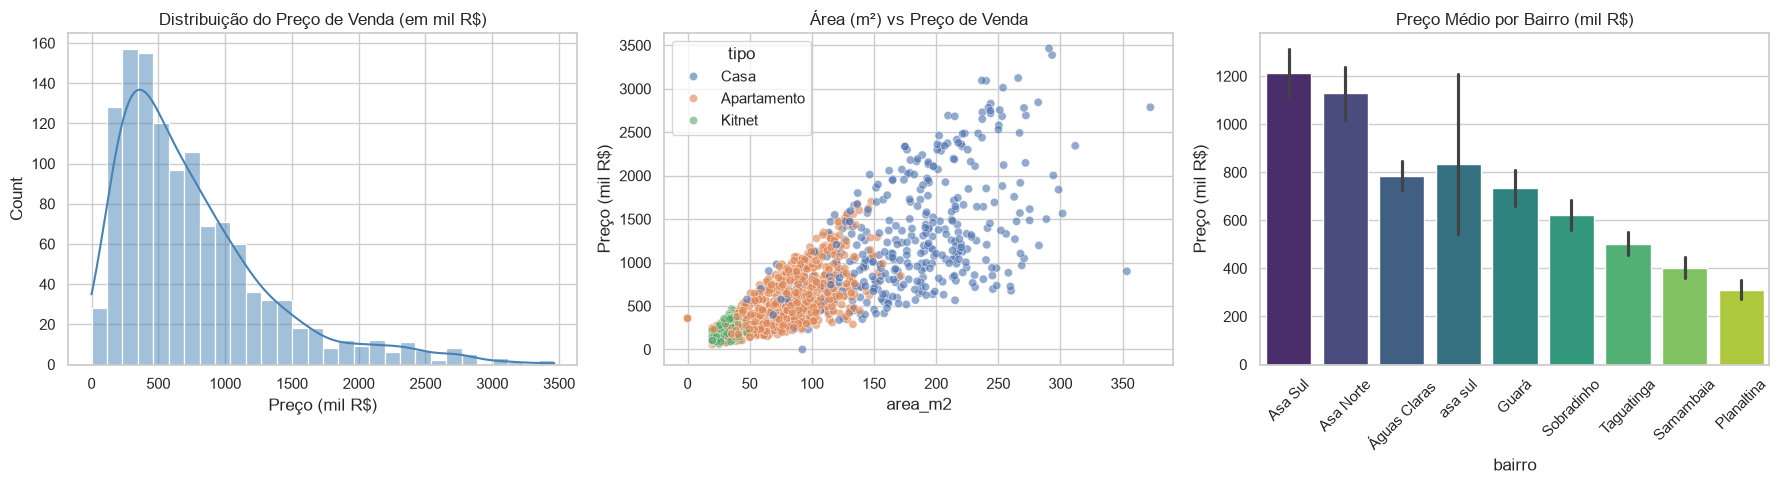

In [1]:
# ==============================================================================
# FASE 2: ENTENDIMENTO DOS DADOS (CRISP-DM - Itens 2.1 a 2.4)
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# ------------------------------------------------------------------------------
# 2.1 Coleta Inicial
# ------------------------------------------------------------------------------
df_imoveis = pd.read_csv("../data/raw/imoveis.csv")
df_bairros = pd.read_csv("../data/raw/indicadores_bairros.csv")

print("=== 2.1 COLETA INICIAL ===")
print(f"Base Imóveis: {df_imoveis.shape[0]} linhas x {df_imoveis.shape[1]} colunas")
print(f"Base Indicadores por Bairro: {df_bairros.shape[0]} linhas x {df_bairros.shape[1]} colunas\n")

# ------------------------------------------------------------------------------
# 2.2 Descrição dos Dados
# ------------------------------------------------------------------------------
print("=== 2.2 DESCRIÇÃO DOS DADOS (TIPOS E ESTATÍSTICAS) ===")
print(df_imoveis.info())
display(df_imoveis.describe().round(2))
display(df_bairros)

# ------------------------------------------------------------------------------
# 2.4 Verificação da Qualidade dos Dados
# ------------------------------------------------------------------------------
print("\n=== 2.4 VERIFICAÇÃO DA QUALIDADE ===")
print("1) Valores ausentes (nulos) por coluna:")
print(df_imoveis.isnull().sum()[df_imoveis.isnull().sum() > 0])

print(f"\n2) Registros duplicados exatos: {df_imoveis.duplicated().sum()}")

print("\n3) Inconsistências de texto em 'bairro':")
print(df_imoveis["bairro"].value_counts())

print("\n4) Outliers / Erros de digitação detectados:")
erros_area = df_imoveis[(df_imoveis["area_m2"] <= 10) | (df_imoveis["area_m2"] > 2000)]
erros_preco = df_imoveis[(df_imoveis["preco_venda"] < 50000) | (df_imoveis["preco_venda"] > 10000000)]
erros_quartos = df_imoveis[df_imoveis["quartos"] > 15]
print(f"- Erros de área (<=10m² ou >2000m²): {len(erros_area)} registros")
print(f"- Erros de preço (<R$50k ou >R$10M): {len(erros_preco)} registros")
print(f"- Erros de quartos (>15 quartos): {len(erros_quartos)} registros")
print("- Dado sensível identificado na base: coluna 'cpf_proprietario' (deve ser removida na Fase 3).")

# ------------------------------------------------------------------------------
# 2.3 Exploração dos Dados (Gráficos e Hipóteses Iniciais)
# ------------------------------------------------------------------------------
# Filtro temporário só para os gráficos não ficarem achatados pelos outliers absurdos
df_plot = df_imoveis[(df_imoveis["preco_venda"] < 5000000) & (df_imoveis["area_m2"] < 1000)]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Distribuição de Preços
sns.histplot(df_plot["preco_venda"] / 1000, bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribuição do Preço de Venda (em mil R$)")
axes[0].set_xlabel("Preço (mil R$)")

# Gráfico 2: Área vs Preço
sns.scatterplot(data=df_plot, x="area_m2", y=df_plot["preco_venda"] / 1000, hue="tipo", alpha=0.6, ax=axes[1])
axes[1].set_title("Área (m²) vs Preço de Venda")
axes[1].set_ylabel("Preço (mil R$)")

# Gráfico 3: Preço médio por Bairro
ordem_bairros = df_plot.groupby("bairro")["preco_venda"].median().sort_values(ascending=False).index
sns.barplot(data=df_plot, x="bairro", y=df_plot["preco_venda"] / 1000, order=ordem_bairros, ax=axes[2], palette="viridis")
axes[2].set_title("Preço Médio por Bairro (mil R$)")
axes[2].tick_params(axis="x", rotation=45)
axes[2].set_ylabel("Preço (mil R$)")

plt.tight_layout()
plt.show()